# Análise do ensaio embarcado

Este notebook interpreta o log produzido por `notebooks/model_teste.ipynb`
em `results/ensaio/board_test.csv`. Ele não abre a serial nem executa o
firmware: lê o CSV, reconstrói a duração dos blocos artificiais e gera as
figuras e tabelas da análise.

Convenções:

- **gap artificial**: linhas com `gap=True`, criadas por `common.gaps` com
  duração de relógio conhecida. O PCA real continua disponível e serve de
  referência.
- **gap real**: ausência de linha por mais de 16 h entre leituras
  consecutivas. A série é quebrada nesses intervalos; a variação normal
  entre o fim de um dia e o começo do seguinte fica em 13 a 14 h.
- **tempo de inferência**: `inference_us`, medido no firmware ao redor de
  `runInference()` e gravado por amostra.

As figuras vão para `results/figuras/`; as tabelas, em CSV e Markdown, para
`results/ensaio/`. A cópia para `docs/figuras/` é manual.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# Raiz do repo: funciona com cwd em notebooks/ ou na raiz.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "models" / "src").is_dir())
sys.path.insert(0, str(RAIZ / "models" / "src"))

from common import paths, plots, results, server

for _s in (sys.stdout, sys.stderr):
    try:
        _s.reconfigure(encoding="utf-8", errors="replace")
    except (AttributeError, ValueError):
        pass

INV_DETALHE = "ifpee1"
INVERSORES = ("ifpee1", "ifpee2", "ifpee3")
LIMIAR_GAP_CURTO = pd.Timedelta(hours=6)
LIMIAR_NOITE = pd.Timedelta(hours=16)
LIMIAR_GAP_REAL = LIMIAR_NOITE
JANELA_MEDIA = pd.Timedelta(days=7)
AQUECIMENTO = 6
PREFIXO = "analise_"
SUBPASTA = "ensaio"
LIMITE_KW = 2.0
EXTENSO = (0.0, LIMITE_KW, 0.0, LIMITE_KW)
CONTEXTO_MAX = 12
ROTULO_DURACAO = {1.0: "1 h", 6.0: "6 h", 24.0: "24 h", 72.0: "3 d", 240.0: "10 d", 360.0: "15 d"}
SLUG_DURACAO = {1.0: "1h", 6.0: "6h", 24.0: "24h", 72.0: "3d", 240.0: "10d", 360.0: "15d"}


def salvar_csv(df, nome, subpasta):
    destino = paths.RESULTS / subpasta / f"{nome}.csv"
    destino.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(destino, index=False)
    print(f"  {destino.relative_to(paths.ROOT)}", flush=True)
    return destino


plots.aplicar_estilo()
print(f"ensaio: {paths.ENSAIO / 'board_test.csv'}")

ensaio: C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\results\ensaio\board_test.csv


## Inventário do ensaio

In [2]:
ARQUIVO = paths.ENSAIO / "board_test.csv"
bruto = pd.read_csv(ARQUIVO, parse_dates=["sample"])

necessarias = {"sample", "pred", "real", "inference_us", "inversor",
               "gap", "gap_size"}
faltando = necessarias.difference(bruto.columns)
if faltando:
    raise ValueError(
        "board_test.csv sem as colunas: " + ", ".join(sorted(faltando)) +
        ". Regenere o ensaio com notebooks/model_teste.ipynb.")

partes = []
for inv, d in bruto.groupby("inversor", sort=True):
    d = d.sort_values("sample").reset_index(drop=True)
    if d.empty:
        raise ValueError(f"{inv}: sem linhas no ensaio")
    if d["sample"].isna().any():
        raise ValueError(f"{inv}: sample com data nula")
    d["gap"] = d["gap"].astype(bool)
    d["gap_h"] = pd.to_numeric(d["gap_size"], errors="coerce")
    if d["gap_h"].isna().any():
        raise ValueError(f"{inv}: gap_size nao numerico")
    if not (d.loc[~d["gap"], "gap_h"] == 0).all():
        raise AssertionError(f"{inv}: gap_size fora dos gaps diferente de zero")
    if not (d.loc[d["gap"], "gap_h"] > 0).all():
        raise AssertionError(f"{inv}: gap_size dentro dos gaps nao positivo")
    inicia = d["gap"] & ~d["gap"].shift(fill_value=False)
    d["bloco"] = np.where(d["gap"], inicia.cumsum(), 0).astype(int)
    for k, sub in d[d["gap"]].groupby("bloco"):
        if sub["gap_h"].nunique() != 1:
            raise AssertionError(
                f"{inv}: bloco {k} com mais de uma duracao em gap_size")
    partes.append(d)

ensaio = pd.concat(partes, ignore_index=True)
if tuple(sorted(ensaio["inversor"].unique())) != INVERSORES:
    print("ATENCAO: inversores no CSV:",
          tuple(sorted(ensaio["inversor"].unique())))

resumo_inv = (ensaio.groupby("inversor")
              .agg(linhas=("sample", "size"),
                   gaps=("gap", "sum"),
                   reais_nan=("real", lambda s: s.isna().sum())))
resumo_inv["blocos"] = (ensaio[ensaio["gap"]]
                        .groupby("inversor")["bloco"].nunique())
print(resumo_inv.to_string())

blocos_ifpee1 = (ensaio[(ensaio["inversor"] == INV_DETALHE) & ensaio["gap"]]
                 .groupby("bloco")
                 .agg(inicio=("sample", "min"),
                      fim_observado=("sample", "max"),
                      leituras=("sample", "size"),
                      duracao_h=("gap_h", "first"))
                 .reset_index())
blocos_ifpee1["fim_previsto"] = (
    blocos_ifpee1["inicio"]
    + pd.to_timedelta(blocos_ifpee1["duracao_h"], unit="h"))
print(blocos_ifpee1.to_string(index=False))

          linhas  gaps  reais_nan  blocos
inversor                                 
ifpee1      4042   182          3       6
ifpee2      4042   181          3       6
ifpee3      4042   188          3       6
 bloco              inicio       fim_observado  leituras  duracao_h        fim_previsto
     1 2025-02-13 08:00:00 2025-02-14 07:00:00        12       24.0 2025-02-14 08:00:00
     2 2025-02-14 17:00:00 2025-02-15 16:00:00        12       24.0 2025-02-15 17:00:00
     3 2025-05-22 10:00:00 2025-05-22 15:00:00         6        6.0 2025-05-22 16:00:00
     4 2025-06-22 10:00:00 2025-07-02 09:00:00       110      240.0 2025-07-02 10:00:00
     5 2025-07-15 06:00:00 2025-07-15 11:00:00         6        6.0 2025-07-15 12:00:00
     6 2025-10-21 13:00:00 2025-10-24 12:00:00        36       72.0 2025-10-24 13:00:00


## 1. Série temporal completa

A série usa somente `ifpee1`, para manter o gráfico legível. As linhas de
real e predito são mantidas contínuas na pausa noturna, em buracos menores
que 6 h e nos blocos artificiais. Elas quebram apenas nos buracos reais de
6 h ou mais que não sejam a noite; o gap real de 2025-08-22 16:00 a
2025-09-03 08:00, com 280 h, quebra a série. O detalhe pontilhado dentro dos
blocos artificiais fica no item 2.

A linha grossa é a média móvel de 7 dias; a linha fina e clara é a leitura
bruta. Os blocos artificiais aparecem sombreados no painel principal e na
faixa inferior de marcação; a faixa inferior é o que torna visíveis os
blocos curtos no eixo anual.

  results\ensaio\analise_gaps_reais.csv
             inicio                 fim  horas
2025-08-22 16:00:00 2025-09-03 08:00:00  280.0
  figura: results\figuras\analise_serie_ifpee1.png


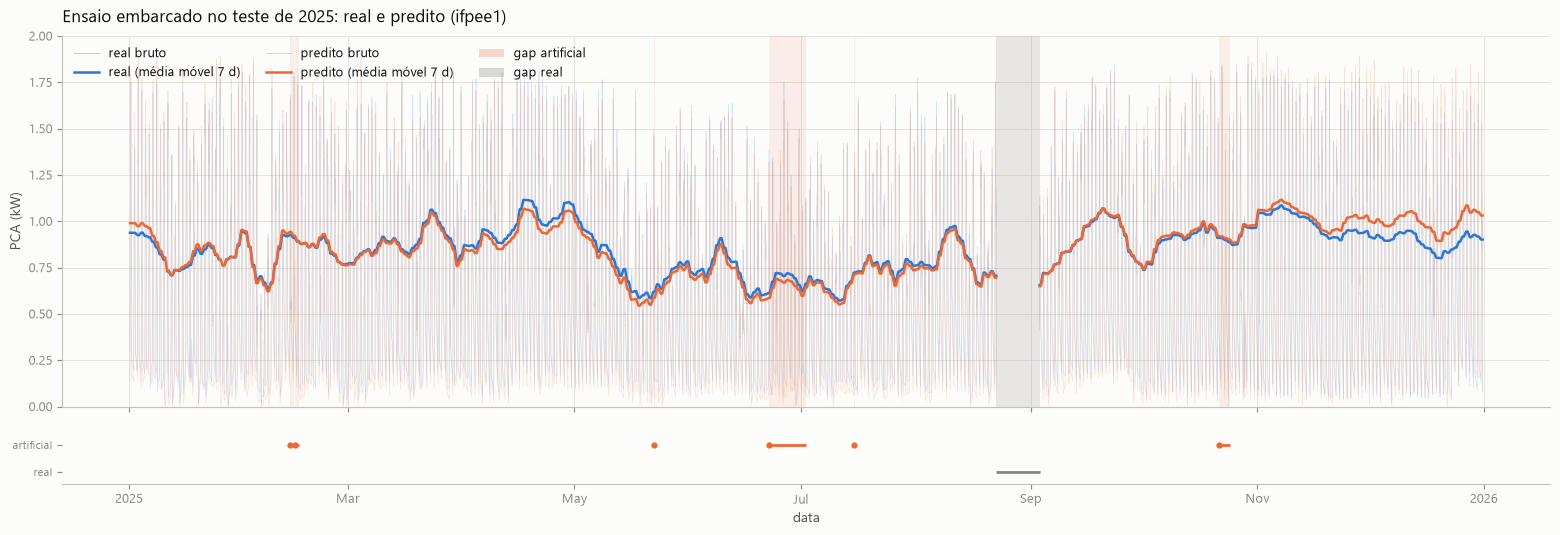

In [3]:
detalhe = (ensaio[ensaio["inversor"] == INV_DETALHE]
           .sort_values("sample").reset_index(drop=True))

dif = detalhe["sample"].diff()
cortes_reais = np.flatnonzero((dif > LIMIAR_GAP_REAL).to_numpy())
gaps_reais = pd.DataFrame([
    {"inicio": detalhe.loc[i - 1, "sample"],
     "fim": detalhe.loc[i, "sample"],
     "horas": dif.iloc[i] / pd.Timedelta(hours=1)}
    for i in cortes_reais
])
salvar_csv(gaps_reais, f"{PREFIXO}gaps_reais", SUBPASTA)
print(gaps_reais.to_string(index=False))

def plot_segmentada(ax, d, coluna, cor, janela):
    # Interpola a noite, os buracos com menos de 6 h e os blocos artificiais;
    # quebra nos buracos reais de 6 h ou mais que nao sejam a pausa noturna.
    dif = d["sample"].diff()
    noite = (d["sample"].dt.date.ne(d["sample"].shift().dt.date)
             & (dif <= LIMIAR_NOITE))
    quebra = (dif >= LIMIAR_GAP_CURTO) & ~noite
    bordas = np.r_[0, np.flatnonzero(quebra.to_numpy()), len(d)]
    for i in range(len(bordas) - 1):
        seg = d.iloc[bordas[i]:bordas[i + 1]]
        serie = seg.set_index("sample")[coluna]
        media = serie.rolling(janela, center=True, min_periods=1).mean()
        media = media.where(serie.notna())
        ax.plot(seg["sample"], seg[coluna], color=cor, lw=0.5,
                alpha=0.18, zorder=1)
        ax.plot(media.index, media.values, color=cor, lw=1.8, zorder=2)

fig, (ax, ax_faixa) = plt.subplots(
    2, 1, figsize=(16, 5.6), sharex=True,
    gridspec_kw={"height_ratios": [4.0, 0.65]})
plot_segmentada(ax, detalhe, "real", plots.REAL, JANELA_MEDIA)
plot_segmentada(ax, detalhe, "pred", plots.PREDITO, JANELA_MEDIA)

for _, b in blocos_ifpee1.iterrows():
    ax.axvspan(b["inicio"], b["fim_previsto"], color=plots.PREDITO,
               alpha=0.10, lw=0)
    ax_faixa.hlines(0.65, b["inicio"], b["fim_previsto"],
                    color=plots.PREDITO, lw=2.0)
    ax_faixa.plot(b["inicio"], 0.65, marker="o", ms=3.5,
                  color=plots.PREDITO, ls="none")
for _, g in gaps_reais.iterrows():
    ax.axvspan(g["inicio"], g["fim"], color=plots.MUDO,
               alpha=0.18, lw=0)
    ax_faixa.hlines(0.20, g["inicio"], g["fim"],
                    color=plots.MUDO, lw=2.0)

ax.set_ylim(0, LIMITE_KW)
plots.enfeitar(
    ax,
    f"Ensaio embarcado no teste de 2025: real e predito ({INV_DETALHE})",
    "", "PCA (kW)")
rotulo_media = f"média móvel {JANELA_MEDIA / pd.Timedelta(days=1):g} d"
handles = [
    plt.Line2D([], [], color=plots.REAL, lw=0.7, alpha=0.35,
               label="real bruto"),
    plt.Line2D([], [], color=plots.REAL, lw=1.8,
               label=f"real ({rotulo_media})"),
    plt.Line2D([], [], color=plots.PREDITO, lw=0.7, alpha=0.35,
               label="predito bruto"),
    plt.Line2D([], [], color=plots.PREDITO, lw=1.8,
               label=f"predito ({rotulo_media})"),
    Patch(facecolor=plots.PREDITO, alpha=0.25, edgecolor="none",
          label="gap artificial"),
    Patch(facecolor=plots.MUDO, alpha=0.30, edgecolor="none",
          label="gap real"),
]
ax.legend(handles=handles, frameon=False, loc="upper left", ncol=3,
          fontsize=9, labelcolor=plots.TINTA)

ax_faixa.set_ylim(0, 1)
ax_faixa.set_yticks([0.20, 0.65], ["real", "artificial"])
ax_faixa.set_xlabel("data", color=plots.TINTA_2, fontsize=10)
ax_faixa.tick_params(axis="x", colors=plots.MUDO, labelsize=9)
ax_faixa.tick_params(axis="y", colors=plots.MUDO, labelsize=8)
for lado in ("top", "right", "left"):
    ax_faixa.spines[lado].set_visible(False)
ax_faixa.spines["bottom"].set_color(plots.EIXO)
ax_faixa.grid(False)
loc = mdates.AutoDateLocator(minticks=6, maxticks=12)
ax_faixa.xaxis.set_major_locator(loc)
ax_faixa.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
fig.subplots_adjust(top=0.90, bottom=0.10, left=0.06, right=0.99,
                    hspace=0.08)
plots.salvar_figura(fig, f"{PREFIXO}serie_{INV_DETALHE}.png")
plt.show()

## 2. Zoom nos blocos artificiais

As figuras são separadas por duração e por inversor. Cada figura mostra os
blocos daquela duração para uma usina, sem título. A legenda de cada painel
traz apenas o início do gap, o final do gap e o número de medidas no
intervalo. O contexto antes e depois é de até 12 leituras para gaps maiores
que 24 h; nos demais, entram `n` leituras de cada lado.

  figura: results\figuras\analise_blocos_6h_ifpee1.png


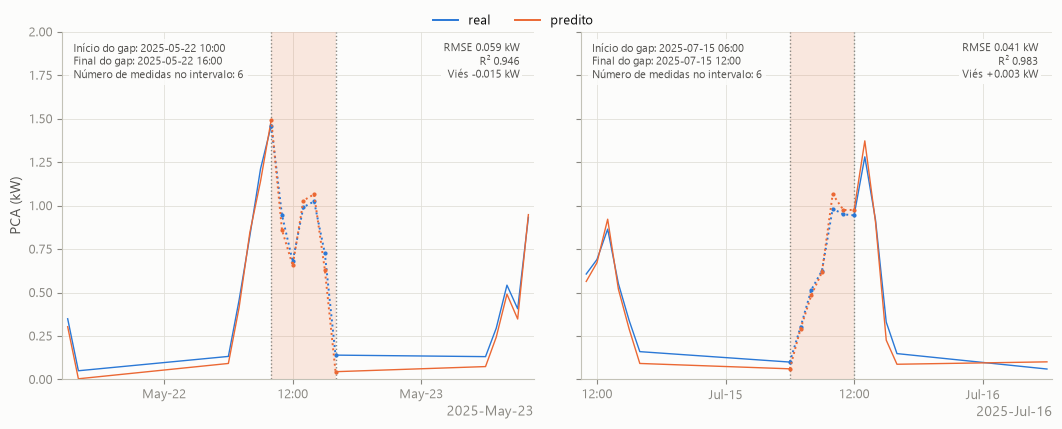

  figura: results\figuras\analise_blocos_6h_ifpee2.png


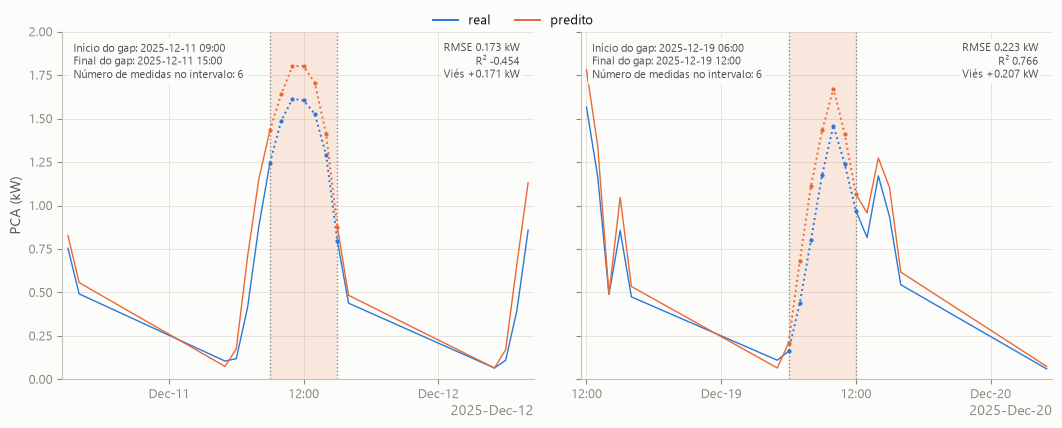

  figura: results\figuras\analise_blocos_6h_ifpee3.png


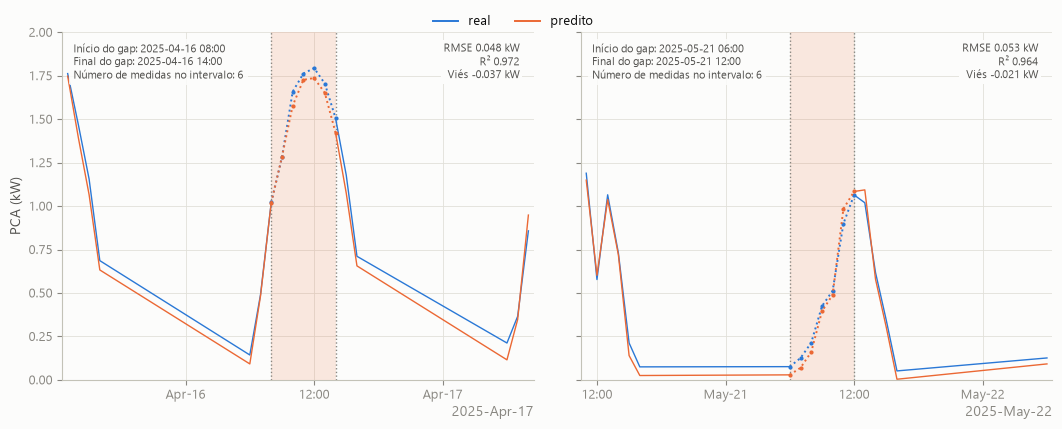

  figura: results\figuras\analise_blocos_24h_ifpee1.png


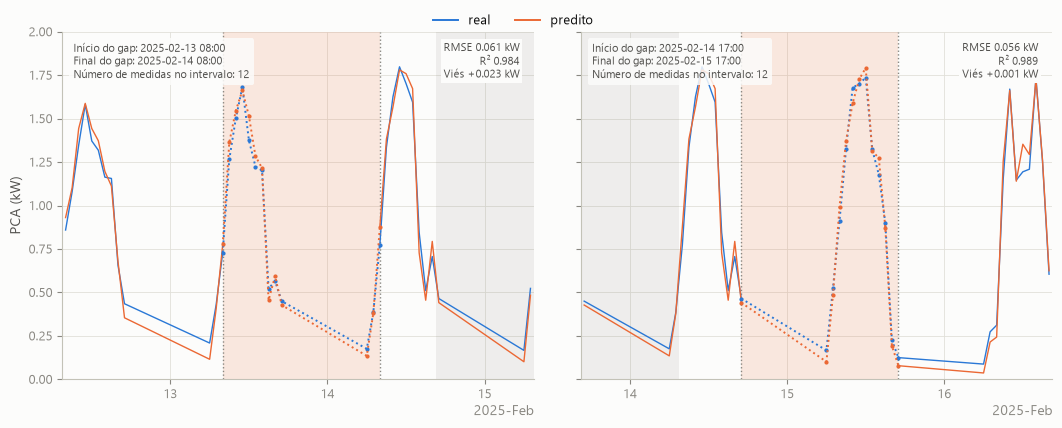

  figura: results\figuras\analise_blocos_24h_ifpee2.png


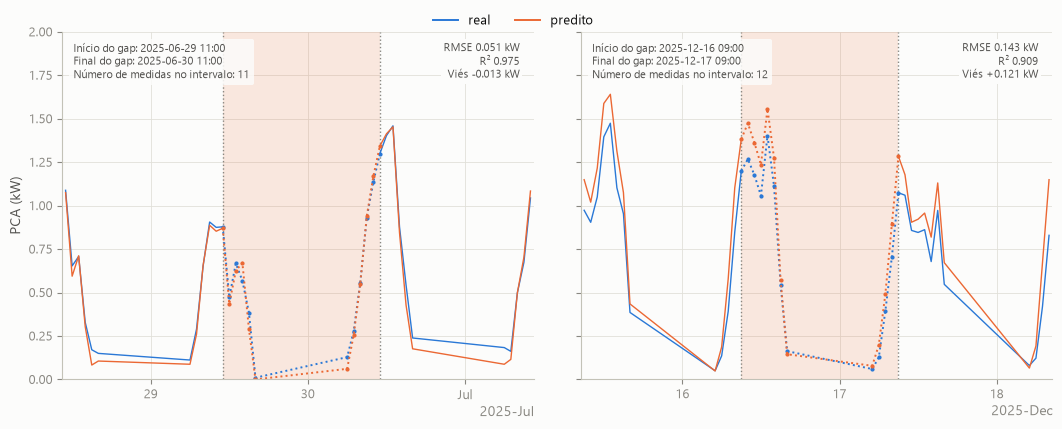

  figura: results\figuras\analise_blocos_24h_ifpee3.png


c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\models\src\common\plots.py:48: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.savefig(destino, dpi=dpi, bbox_inches=bbox_inches)
c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 12.
  fig.canvas.print_figure(bytes_io, **kw)


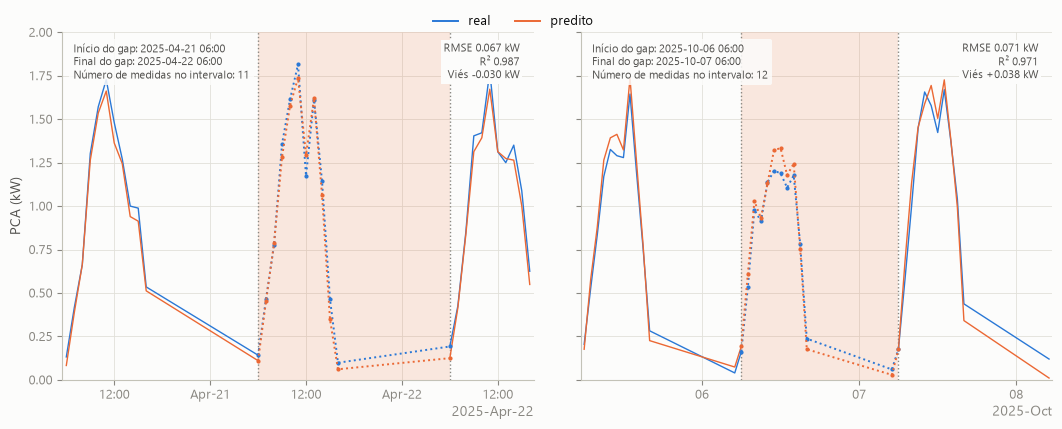

  figura: results\figuras\analise_blocos_3d_ifpee1.png


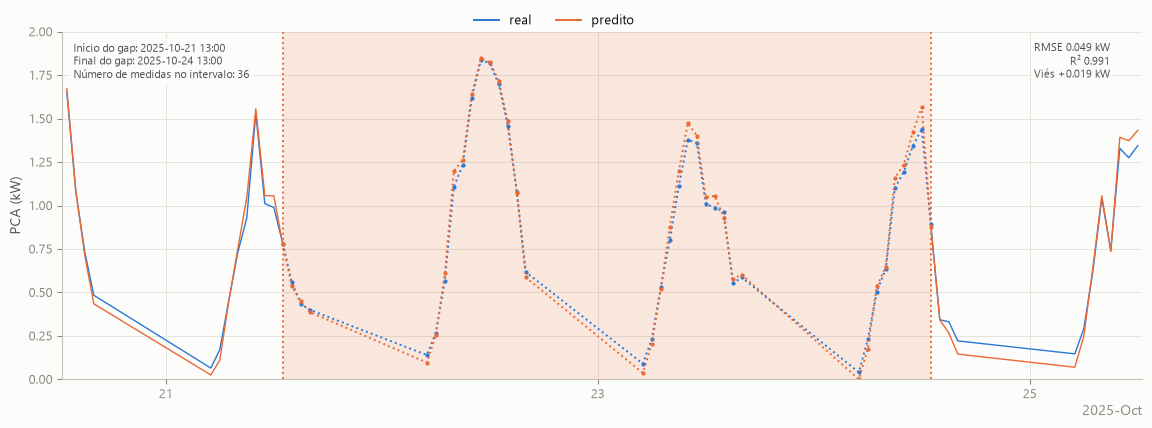

  figura: results\figuras\analise_blocos_3d_ifpee2.png


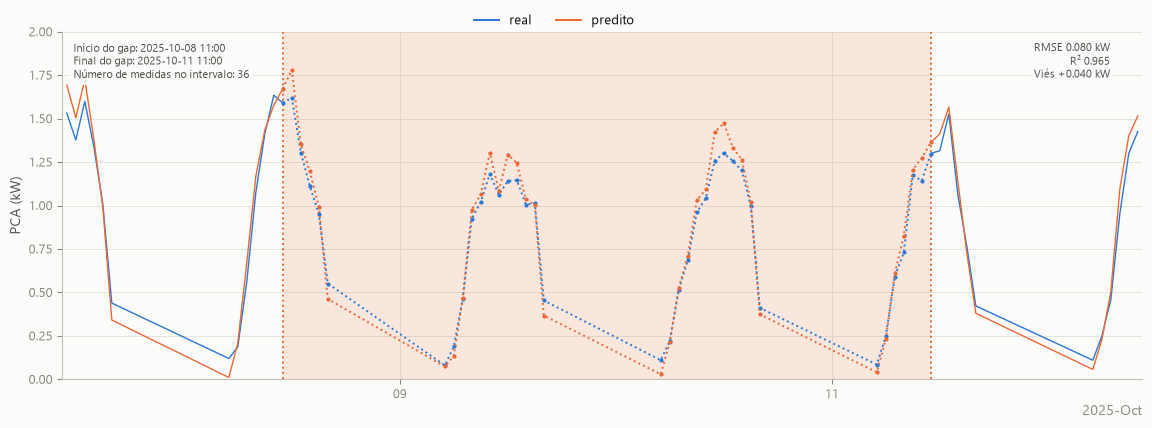

  figura: results\figuras\analise_blocos_3d_ifpee3.png


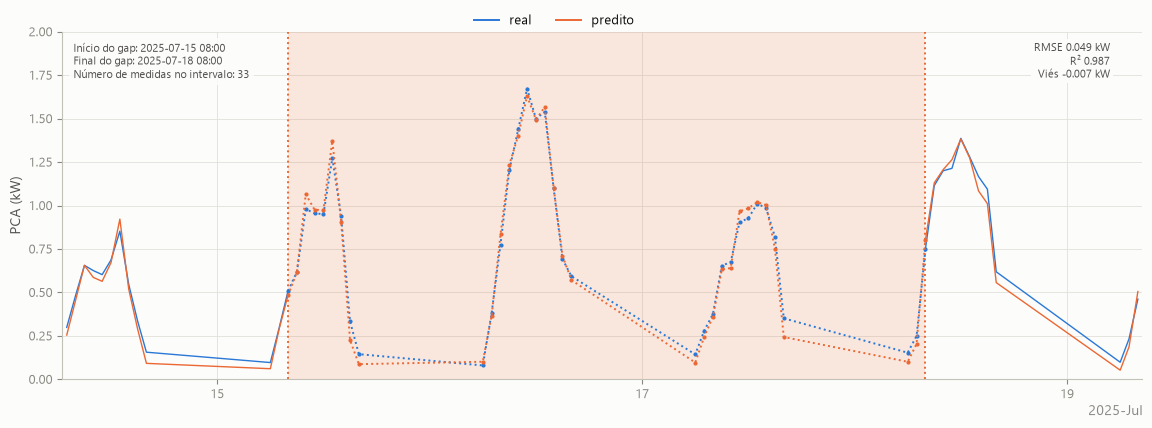

  figura: results\figuras\analise_blocos_10d_ifpee1.png


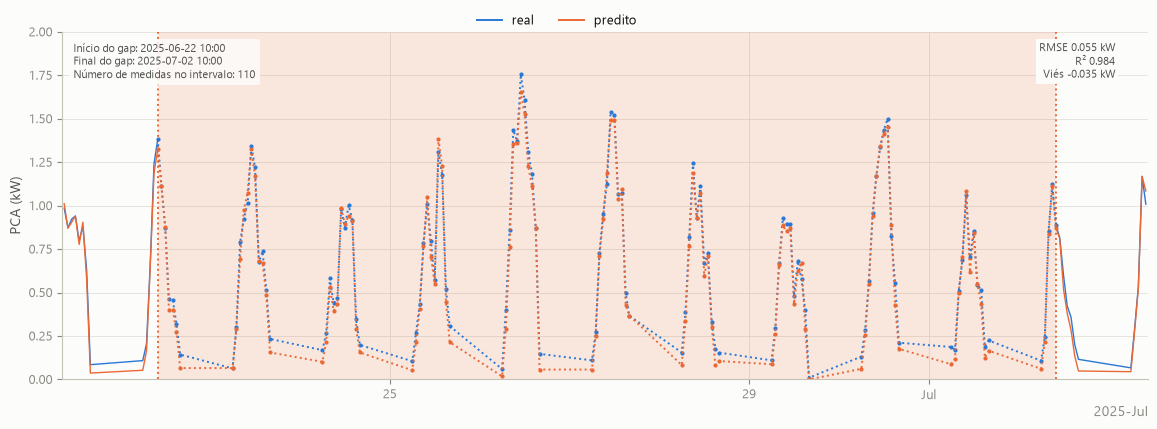

  figura: results\figuras\analise_blocos_10d_ifpee2.png


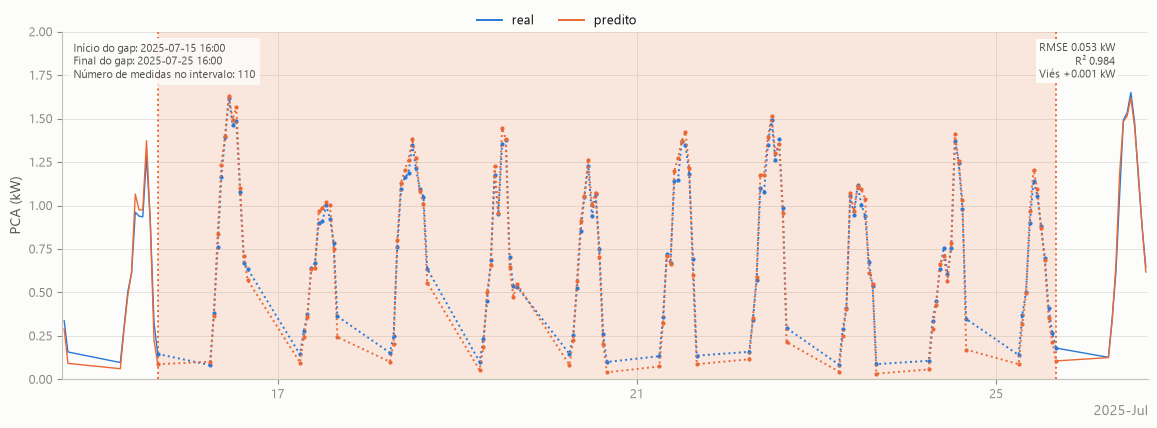

  figura: results\figuras\analise_blocos_10d_ifpee3.png


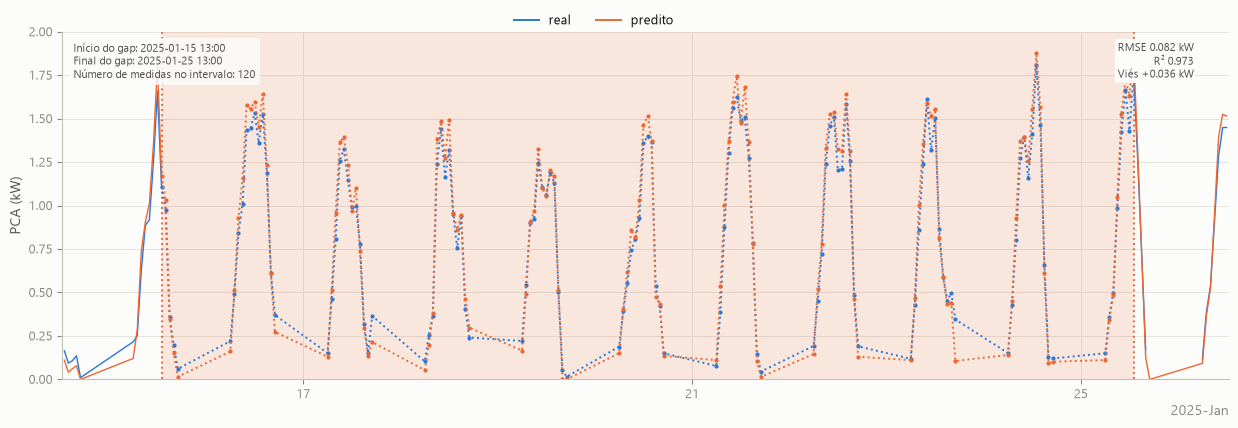

In [4]:
blocos = (ensaio[ensaio["gap"]]
          .groupby(["inversor", "bloco"])
          .agg(inicio=("sample", "min"),
               fim_observado=("sample", "max"),
               leituras=("sample", "size"),
               duracao_h=("gap_h", "first"))
          .reset_index())
dados_inv = {inv: ensaio[ensaio["inversor"] == inv]
               .sort_values("sample").reset_index(drop=True)
             for inv in INVERSORES}

for dur in sorted(blocos["duracao_h"].unique()):
    slug = SLUG_DURACAO.get(float(dur), f"{dur:g}h")
    for inv in INVERSORES:
        sel = (blocos[(blocos["inversor"] == inv)
                      & (blocos["duracao_h"] == dur)]
               .sort_values("inicio"))
        if sel.empty:
            continue
        ncols = len(sel)
        destacar = dur >= 72
        if ncols > 1:
            largura = 5.5 * ncols
        else:
            n0 = int(sel.iloc[0]["leituras"])
            contexto0 = n0 if float(dur) <= 24 else min(n0, CONTEXTO_MAX)
            largura = max(12.0 if destacar else 6.0,
                          0.09 * (n0 + 2 * contexto0))
        fig, eixos = plt.subplots(
            1, ncols, figsize=(largura, 4.4), sharey=True, squeeze=False)
        eixos = eixos.ravel()
        d = dados_inv[inv]

        for j, (_, b) in enumerate(sel.iterrows(), start=1):
            ax = eixos[j - 1]
            k = int(b["bloco"])
            pos = np.flatnonzero(d["bloco"].to_numpy() == k)
            if not len(pos):
                ax.set_visible(False)
                continue
            n = len(pos)
            contexto = (n if float(b["duracao_h"]) <= 24
                        else min(n, CONTEXTO_MAX))
            ini = max(0, pos[0] - contexto)
            fim = min(len(d), pos[-1] + 1 + contexto)
            janela = d.iloc[ini:fim]
            gap_local = janela["bloco"].to_numpy() == k
            foco = janela[gap_local]
            inicio = b["inicio"]
            fim_prev = inicio + pd.Timedelta(hours=float(b["duracao_h"]))

            vizinhos = janela.loc[janela["gap"] & ~gap_local]
            for k_out in vizinhos["bloco"].unique():
                sub = vizinhos[vizinhos["bloco"] == k_out]
                ax.axvspan(sub["sample"].min() - pd.Timedelta(minutes=30),
                           sub["sample"].max() + pd.Timedelta(minutes=30),
                           color=plots.MUDO, alpha=0.12, lw=0)

            if destacar:
                ax.axvspan(inicio, fim_prev, color=plots.PREDITO,
                           alpha=0.14, lw=0)
                ax.axvline(inicio, color=plots.PREDITO, ls=":", lw=1.4)
                ax.axvline(fim_prev, color=plots.PREDITO, ls=":", lw=1.4)
            else:
                ax.axvspan(inicio, fim_prev, color=plots.PREDITO,
                           alpha=0.14, lw=0)
                ax.axvline(inicio, color=plots.MUDO, ls=":", lw=1.0)
                ax.axvline(fim_prev, color=plots.MUDO, ls=":", lw=1.0)

            serie = janela.set_index("sample")[["real", "pred"]]
            if fim_prev not in serie.index:
                idx = serie.index.union(pd.DatetimeIndex([fim_prev]))
                serie = serie.reindex(idx).interpolate(method="time")
            dentro = (serie.index >= inicio) & (serie.index <= fim_prev)
            estrito = (serie.index > inicio) & (serie.index < fim_prev)
            solido = serie.copy()
            solido.loc[estrito] = np.nan
            pontilhado = serie.copy()
            pontilhado.loc[~dentro] = np.nan
            ax.plot(solido.index, solido["real"], color=plots.REAL, lw=1.0)
            ax.plot(solido.index, solido["pred"], color=plots.PREDITO,
                    lw=1.0)
            ax.plot(pontilhado.index, pontilhado["real"], color=plots.REAL,
                    lw=1.4, ls=":", marker=".", ms=4)
            ax.plot(pontilhado.index, pontilhado["pred"], color=plots.PREDITO,
                    lw=1.4, ls=":", marker=".", ms=4)

            handles = [
                plt.Line2D([], [], color=plots.MUDO, ls=":", lw=1.0),
                plt.Line2D([], [], color=plots.MUDO, ls=":", lw=1.0),
                plt.Line2D([], [], color=plots.PREDITO, lw=0),
            ]
            labels = [
                f"Início do gap: {inicio:%Y-%m-%d %H:%M}",
                f"Final do gap: {fim_prev:%Y-%m-%d %H:%M}",
                f"Número de medidas no intervalo: {n}",
            ]
            ax.legend(handles, labels, loc="upper left", frameon=True,
                      facecolor=plots.SUPERFICIE, edgecolor="none",
                      framealpha=0.85, fontsize=8,
                      labelcolor=plots.TINTA_2, handlelength=0,
                      handletextpad=0, borderaxespad=0.6,
                      labelspacing=0.2)

            m = server.eval_metrics(foco)
            texto_metricas = chr(10).join([
                f"RMSE {m['rmse']:.3f} kW",
                f"R² {m['r2']:.3f}",
                f"Viés {m['vies']:+.3f} kW",
            ])
            ax.text(0.97, 0.97, texto_metricas, transform=ax.transAxes,
                    ha="right", va="top", color=plots.TINTA_2,
                    fontsize=8, bbox=plots.HALO)

            ax.set_ylim(0, LIMITE_KW)
            ax.set_xlim(janela["sample"].min() - pd.Timedelta(minutes=30),
                        janela["sample"].max() + pd.Timedelta(minutes=30))
            plots.enfeitar(ax, "", "", "PCA (kW)")
            loc = mdates.AutoDateLocator(minticks=3, maxticks=5)
            ax.xaxis.set_major_locator(loc)
            ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
            if j > 1:
                ax.set_ylabel("")

        handles_series = [
            plt.Line2D([], [], color=plots.REAL, lw=1.4, label="real"),
            plt.Line2D([], [], color=plots.PREDITO, lw=1.4,
                       label="predito"),
        ]
        fig.legend(handles=handles_series, loc="upper center", ncol=2,
                   frameon=False, fontsize=9, labelcolor=plots.TINTA,
                   bbox_to_anchor=(0.5, 0.995))
        fig.subplots_adjust(top=0.93, bottom=0.14, left=0.09, right=0.99,
                            wspace=0.10)
        plots.salvar_figura(fig, f"{PREFIXO}blocos_{slug}_{inv}.png")
        plt.show()

## 3. Desempenho geral do modelo embarcado

O conjunto válido exclui as linhas com `real` NaN, que são a sentinela de
`PCA == 0` do pré-processamento. A tabela separa o teste completo, as
amostras fora dos gaps e as amostras dentro dos gaps, para cada usina e
para o conjunto das três. O tempo de inferência é resumido sobre todas as
predições logadas; a média bruta é comparada com a média sem as primeiras
seis amostras de cada usina, que incluem o aquecimento do firmware.

  results\ensaio\analise_metricas.csv
         escopo inversor     n  MAE (kW)  RMSE (kW)     R²  viés (kW)  MAPE (%)  P90 (kW)  inferência média (µs)  inferência P90 (µs)
          total    todos 12117    0.0585     0.0765 0.9756     0.0145   12.2934    0.1246               991.9002                978.0
          total   ifpee1  4039    0.0549     0.0699 0.9801     0.0048   11.9605    0.1115               991.9107                978.0
          total   ifpee2  4039    0.0629     0.0844 0.9692     0.0291   12.8785    0.1405               991.8904                978.0
          total   ifpee3  4039    0.0577     0.0746 0.9772     0.0096   12.0410    0.1203               991.8996                978.0
  fora dos gaps    todos 11566    0.0586     0.0767 0.9756     0.0147   12.2881    0.1252               992.5817                978.0
  fora dos gaps   ifpee1  3857    0.0553     0.0705 0.9798     0.0058   11.9697    0.1129               992.5834                978.0
  fora dos gaps   ifpee2

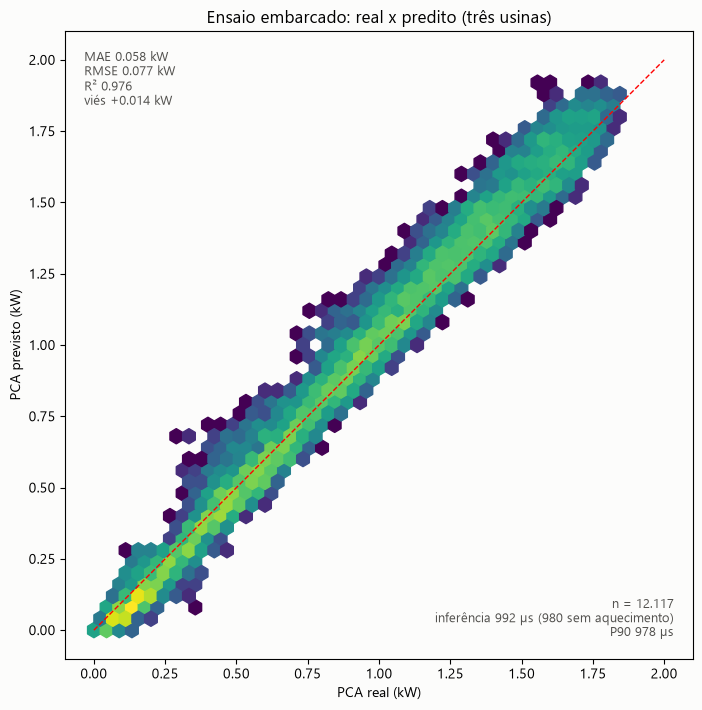

In [5]:
def linha_metricas(escopo, inversor, df):
    m = server.eval_metrics(df)
    return {
        "escopo": escopo,
        "inversor": inversor,
        "n": m["amostras"],
        "MAE (kW)": m["mae"],
        "RMSE (kW)": m["rmse"],
        "R²": m["r2"],
        "viés (kW)": m["vies"],
        "MAPE (%)": m["mape"],
        "P90 (kW)": m["p90"],
        "inferência média (µs)": m["inf_us_media"],
        "inferência P90 (µs)": m["inf_us_p90"],
    }

linhas = []
for escopo, sub in (("total", ensaio),
                    ("fora dos gaps", ensaio[~ensaio["gap"]]),
                    ("dentro dos gaps", ensaio[ensaio["gap"]])):
    linhas.append(linha_metricas(escopo, "todos", sub))
    for inv in INVERSORES:
        linhas.append(linha_metricas(
            escopo, inv, sub[sub["inversor"] == inv]))
metricas = pd.DataFrame(linhas)
salvar_csv(metricas, f"{PREFIXO}metricas", SUBPASTA)
print(metricas.round(4).to_string(index=False))

def resumo_inferencia(df):
    tempos = []
    for _, g in df.groupby("inversor"):
        s = pd.to_numeric(g.sort_values("sample")["inference_us"],
                          errors="coerce").dropna()
        tempos.append(s.iloc[AQUECIMENTO:])
    steady = pd.concat(tempos) if tempos else pd.Series(dtype=float)
    geral = pd.to_numeric(df["inference_us"], errors="coerce").dropna()
    return {
        "n": int(len(geral)),
        "média geral (µs)": float(geral.mean()),
        "P90 geral (µs)": float(geral.quantile(0.90)),
        "média sem aquecimento (µs)": float(steady.mean()),
        "P90 sem aquecimento (µs)": float(steady.quantile(0.90)),
        "amostras descartadas": int(AQUECIMENTO * df["inversor"].nunique()),
    }

inf_linhas = [{"inversor": "todos", **resumo_inferencia(ensaio)}]
for inv in INVERSORES:
    inf_linhas.append({
        "inversor": inv,
        **resumo_inferencia(ensaio[ensaio["inversor"] == inv])})
inferencia = pd.DataFrame(inf_linhas)
salvar_csv(inferencia, f"{PREFIXO}inferencia", SUBPASTA)
print(inferencia.round(1).to_string(index=False))

validos = ensaio.dropna(subset=["real", "pred"]).copy()
m_total = server.eval_metrics(validos)
inf_todos = inferencia.loc[inferencia["inversor"] == "todos"].iloc[0]

fig, ax = plt.subplots(figsize=(8.4, 7.2))
plots.hexbin_real_vs_pred(
    ax, validos["real"], validos["pred"],
    titulo="Ensaio embarcado: real x predito (três usinas)",
    extent=EXTENSO, gridsize=45)
texto = "\n".join([
    f"MAE {m_total['mae']:.3f} kW",
    f"RMSE {m_total['rmse']:.3f} kW",
    f"R² {m_total['r2']:.3f}",
    f"viés {m_total['vies']:+.3f} kW",
])
ax.text(0.03, 0.97, texto, transform=ax.transAxes, va="top",
        color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
texto_inf = "\n".join([
    f"n = {m_total['amostras']:,}".replace(",", "."),
    f"inferência {inf_todos['média geral (µs)']:.0f} µs "
    f"({inf_todos['média sem aquecimento (µs)']:.0f} sem aquecimento)",
    f"P90 {inf_todos['P90 geral (µs)']:.0f} µs",
])
ax.text(0.97, 0.03, texto_inf, transform=ax.transAxes, va="bottom",
        ha="right", color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plots.salvar_figura(fig, f"{PREFIXO}hexbin_total.png")
plt.show()

## 4. Desempenho somente dentro dos gaps

O conjunto reúne as linhas com `gap=True` e `real` válido nas três usinas.
As durações menores e os blocos que caem sobre horários já ausentes na
série real têm poucas amostras, então o R² bruto de grupos pequenos pode
ficar negativo ou absurdo. A coluna `R² reportável` indica os grupos com
pelo menos 10 amostras e dispersão de `real` maior que zero; o valor bruto
fica no CSV para auditoria.

  results\ensaio\analise_gaps_duracao.csv
duração inversor  blocos   n  MAE (kW)  RMSE (kW)     R²  R² reportável  viés (kW)  MAPE (%)  P90 (kW)  inferência média (µs)  inferência P90 (µs)
    6 h    todos       5  36    0.0919     0.1224 0.9452           True     0.0513   14.0703    0.2050               977.3889                978.0
    6 h   ifpee1       2  12    0.0427     0.0509 0.9787           True    -0.0059    8.0366    0.0851               977.5833                978.0
    6 h   ifpee2       2  12    0.1888     0.1993 0.8023           True     0.1888   20.3100    0.2535               976.9167                978.0
    6 h   ifpee3       2  12    0.0440     0.0509 0.9938           True    -0.0291   13.8643    0.0785               977.6667                978.0
   24 h    todos       5  70    0.0630     0.0816 0.9736           True     0.0247   13.2094    0.1455               978.1571                978.0
   24 h   ifpee1       2  24    0.0493     0.0589 0.9870           True     

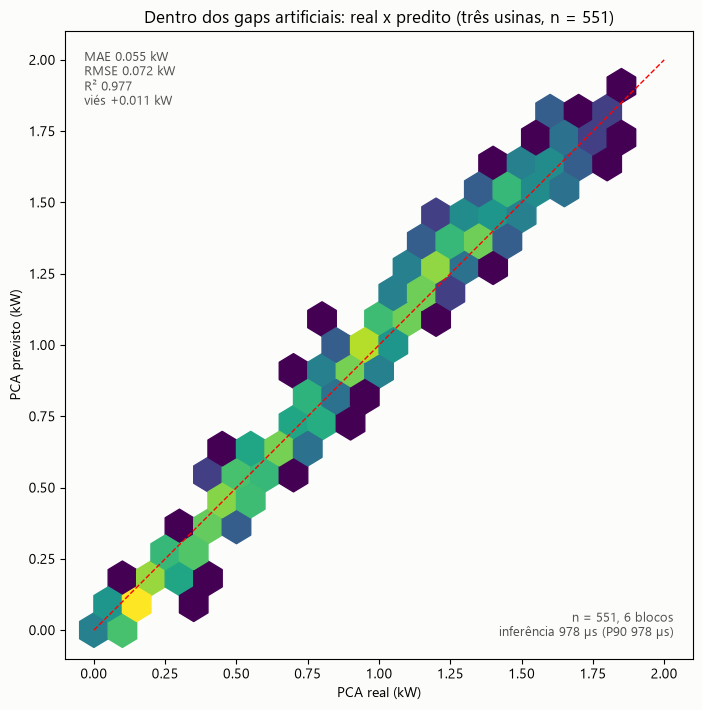

In [6]:
dentro = ensaio[ensaio["gap"]].dropna(subset=["real", "pred"]).copy()
if dentro.empty:
    raise ValueError("nao ha linhas em gaps com real valido")
m_dentro = server.eval_metrics(dentro)

DURACOES = sorted(dentro["gap_h"].unique())

def r2_reportavel(df):
    real = df["real"].dropna().to_numpy()
    return bool(len(real) >= 10 and np.ptp(real) > 0)

def linha_gap(duracao, inversor, df):
    m = server.eval_metrics(df)
    return {
        "duração": ROTULO_DURACAO.get(float(duracao), f"{duracao:g} h"),
        "inversor": inversor,
        "blocos": int(df["bloco"].nunique()),
        "n": m["amostras"],
        "MAE (kW)": m["mae"],
        "RMSE (kW)": m["rmse"],
        "R²": m["r2"],
        "R² reportável": r2_reportavel(df),
        "viés (kW)": m["vies"],
        "MAPE (%)": m["mape"],
        "P90 (kW)": m["p90"],
        "inferência média (µs)": m["inf_us_media"],
        "inferência P90 (µs)": m["inf_us_p90"],
    }

linhas = []
for h in DURACOES:
    sub_h = dentro[dentro["gap_h"].eq(h)]
    if sub_h.empty:
        continue
    linhas.append(linha_gap(h, "todos", sub_h))
    for inv in INVERSORES:
        sub = sub_h[sub_h["inversor"] == inv]
        if not sub.empty:
            linhas.append(linha_gap(h, inv, sub))
por_duracao = pd.DataFrame(linhas)
salvar_csv(por_duracao, f"{PREFIXO}gaps_duracao", SUBPASTA)
print(por_duracao.round(4).to_string(index=False))

linhas = []
for inv in INVERSORES:
    base = dentro[dentro["inversor"] == inv]
    for k in sorted(base["bloco"].unique()):
        sub = base[base["bloco"] == k]
        if sub.empty:
            continue
        m = server.eval_metrics(sub)
        linhas.append({
            "inversor": inv,
            "bloco": int(k),
            "duração": ROTULO_DURACAO.get(
                float(sub["gap_h"].iloc[0]),
                f"{sub['gap_h'].iloc[0]:g} h"),
            "início": sub["sample"].min().strftime("%Y-%m-%d %H:%M"),
            "fim observado": sub["sample"].max().strftime("%Y-%m-%d %H:%M"),
            "n": m["amostras"],
            "MAE (kW)": m["mae"],
            "RMSE (kW)": m["rmse"],
            "R²": m["r2"],
            "R² reportável": r2_reportavel(sub),
            "viés (kW)": m["vies"],
            "MAPE (%)": m["mape"],
            "P90 (kW)": m["p90"],
            "inferência média (µs)": m["inf_us_media"],
            "inferência P90 (µs)": m["inf_us_p90"],
        })
por_bloco = pd.DataFrame(linhas)
salvar_csv(por_bloco, f"{PREFIXO}gaps_blocos", SUBPASTA)
print(por_bloco.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.4, 7.2))
plots.hexbin_real_vs_pred(
    ax, dentro["real"], dentro["pred"],
    titulo=("Dentro dos gaps artificiais: real x predito "
            f"(três usinas, n = {len(dentro)})"),
    extent=EXTENSO, gridsize=20)
texto = "\n".join([
    f"MAE {m_dentro['mae']:.3f} kW",
    f"RMSE {m_dentro['rmse']:.3f} kW",
    f"R² {m_dentro['r2']:.3f}",
    f"viés {m_dentro['vies']:+.3f} kW",
])
ax.text(0.03, 0.97, texto, transform=ax.transAxes, va="top",
        color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
texto_inf = "\n".join([
    f"n = {m_dentro['amostras']}, {dentro['bloco'].nunique()} blocos",
    f"inferência {m_dentro['inf_us_media']:.0f} µs "
    f"(P90 {m_dentro['inf_us_p90']:.0f} µs)",
])
ax.text(0.97, 0.03, texto_inf, transform=ax.transAxes, va="bottom",
        ha="right", color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plots.salvar_figura(fig, f"{PREFIXO}hexbin_gaps.png")
plt.show()

## Resumo e arquivos

In [7]:
cols_metricas = [
    "escopo", "inversor", "n", "MAE (kW)", "RMSE (kW)", "R²", "viés (kW)",
    "MAPE (%)", "P90 (kW)", "inferência média (µs)", "inferência P90 (µs)",
]
cols_duracao = [
    "duração", "inversor", "blocos", "n", "MAE (kW)", "RMSE (kW)", "R²",
    "R² reportável", "viés (kW)", "MAPE (%)", "P90 (kW)",
    "inferência média (µs)", "inferência P90 (µs)",
]
cols_blocos = [
    "inversor", "bloco", "duração", "início", "fim observado", "n",
    "MAE (kW)", "RMSE (kW)", "R²", "R² reportável", "viés (kW)",
]

total_todos = metricas[(metricas["inversor"] == "todos")
                       & (metricas["escopo"] == "total")].iloc[0]
fora_todos = metricas[(metricas["inversor"] == "todos")
                      & (metricas["escopo"] == "fora dos gaps")].iloc[0]
dentro_todos = metricas[(metricas["inversor"] == "todos")
                        & (metricas["escopo"] == "dentro dos gaps")].iloc[0]
ifpee1_dentro = metricas[(metricas["inversor"] == "ifpee1")
                         & (metricas["escopo"] == "dentro dos gaps")].iloc[0]
inf_todos = inferencia[inferencia["inversor"] == "todos"].iloc[0]
dur_todos = por_duracao[por_duracao["inversor"] == "todos"].copy()
dur_min = dur_todos.loc[dur_todos["MAE (kW)"].idxmin()]
dur_max = dur_todos.loc[dur_todos["MAE (kW)"].idxmax()]
maior_real = gaps_reais["horas"].max() if len(gaps_reais) else 0.0

figuras_blocos = []
links_blocos = []
for h in sorted(ensaio.loc[ensaio["gap"], "gap_h"].unique()):
    slug = SLUG_DURACAO.get(float(h), f"{h:g}h")
    rotulo = ROTULO_DURACAO.get(float(h), f"{h:g} h")
    for inv in INVERSORES:
        p = paths.FIGURAS / f"{PREFIXO}blocos_{slug}_{inv}.png"
        figuras_blocos.append(p)
        links_blocos.append(
            f"![Blocos de {rotulo} - {inv}](figuras/{p.name})")

saidas = [
    paths.FIGURAS / f"{PREFIXO}serie_{INV_DETALHE}.png",
    *figuras_blocos,
    paths.FIGURAS / f"{PREFIXO}hexbin_total.png",
    paths.FIGURAS / f"{PREFIXO}hexbin_gaps.png",
    paths.ENSAIO / f"{PREFIXO}gaps_reais.csv",
    paths.ENSAIO / f"{PREFIXO}metricas.csv",
    paths.ENSAIO / f"{PREFIXO}inferencia.csv",
    paths.ENSAIO / f"{PREFIXO}gaps_duracao.csv",
    paths.ENSAIO / f"{PREFIXO}gaps_blocos.csv",
    paths.RESULTS / f"{PREFIXO}final.md",
]

partes = [
    "# Análise final do ensaio embarcado",
    "",
    "Fonte: `results/ensaio/board_test.csv`, granularidade de 1 h, três "
    "usinas. Este documento reúne a análise completa do ensaio: série "
    "temporal, gaps, métricas gerais, desempenho dentro dos gaps e tempo de "
    "inferência.",
    "",
    "## Convenções",
    "",
    "- **gap artificial**: linha com `gap=True`, com duração de relógio "
    "conhecida. Os valores reais e preditos continuam no CSV e são usados na "
    "avaliação dentro dos gaps.",
    "- **gap real**: ausência de linha por mais de 16 h entre leituras "
    "consecutivas. O maior intervalo do teste é de 280 h.",
    "- **blocos artificiais**: o sorteio não cobre gaps reais "
    "(intervalos maiores que 16 h entre leituras consecutivas) e blocos "
    "menores que 12 h ficam dentro do dia, sem entrar na pausa noturna.",
    "- **série temporal**: as linhas são mantidas contínuas na pausa noturna, "
    "em buracos menores que 6 h e nos blocos artificiais. Elas quebram em "
    "buracos reais de 6 h ou mais que não sejam a noite.",
    "- **tempo de inferência**: `inference_us`, medido no firmware ao redor "
    "de `runInference()` e gravado por amostra.",
    "",
    "## Inventário",
    "",
    f"- Linhas: {len(ensaio)} ({len(ensaio) // len(INVERSORES)} por usina).",
    f"- Linhas em gaps artificiais: {int(ensaio['gap'].sum())} "
    f"({ensaio['gap'].mean() * 100:.1f}%).",
    f"- Blocos artificiais por usina: {len(blocos_ifpee1)}.",
    f"- Gap real: {len(gaps_reais)} bloco(s); maior: {maior_real:.0f} h.",
    f"- Linhas com `real` NaN: {int(ensaio['real'].isna().sum())} "
    "(sentinela de PCA == 0, fora dos gaps).",
    "",
    "### Gaps reais",
    "",
    results.markdown_tabela(gaps_reais.round(2)),
    "",
    "## Série temporal",
    "",
    "A série completa usa somente `ifpee1`. O detalhe dos blocos artificiais "
    "é separado por duração e por inversor; cada figura mostra uma usina e "
    "os blocos daquela duração. Dentro deles, real e predito aparecem "
    "pontilhados.",
    "",
    "![Série completa](figuras/analise_serie_ifpee1.png)",
    "",
    *[item for link in links_blocos for item in (link, "")],
    "",
    "## Métricas gerais",
    "",
    "![Hexbin geral](figuras/analise_hexbin_total.png)",
    "",
    results.markdown_tabela(metricas[cols_metricas].round(4)),
    "",
    "## Métricas dentro dos gaps",
    "",
    "![Hexbin dentro dos gaps](figuras/analise_hexbin_gaps.png)",
    "",
    "### Por duração",
    "",
    results.markdown_tabela(por_duracao[cols_duracao].round(4)),
    "",
    "### Por bloco",
    "",
    results.markdown_tabela(por_bloco[cols_blocos].round(4)),
    "",
    "A coluna `R² reportável` é `False` quando o grupo tem menos de 10 "
    "amostras ou `real` sem dispersão. Nesses casos, o R² bruto fica no CSV, "
    "mas não deve ser citado.",
    "",
    "## Tempo de inferência",
    "",
    results.markdown_tabela(inferencia.round(1)),
    "",
    "## Síntese",
    "",
    f"- No teste completo, MAE de {total_todos['MAE (kW)']:.4f} kW e R² de "
    f"{total_todos['R²']:.4f}.",
    f"- Fora dos gaps, MAE de {fora_todos['MAE (kW)']:.4f} kW e R² de "
    f"{fora_todos['R²']:.4f}.",
    f"- Dentro dos gaps, MAE de {dentro_todos['MAE (kW)']:.4f} kW e R² de "
    f"{dentro_todos['R²']:.4f} nas três usinas; em ifpee1, MAE de "
    f"{ifpee1_dentro['MAE (kW)']:.4f} kW e R² de {ifpee1_dentro['R²']:.4f}.",
    f"- Entre as durações, o menor MAE agregado é o de {dur_min['duração']} "
    f"({dur_min['MAE (kW)']:.4f} kW) e o maior é o de {dur_max['duração']} "
    f"({dur_max['MAE (kW)']:.4f} kW).",
    f"- Inferência: média bruta de {inf_todos['média geral (µs)']:.1f} µs, "
    f"{inf_todos['média sem aquecimento (µs)']:.1f} µs sem aquecimento e P90 "
    f"de {inf_todos['P90 geral (µs)']:.1f} µs.",
    "",
    "## Arquivos",
    "",
    "### Figuras",
    "",
    "- `figuras/analise_serie_ifpee1.png`",
    *[f"- `figuras/{p.name}`" for p in figuras_blocos],
    "- `figuras/analise_hexbin_total.png`",
    "- `figuras/analise_hexbin_gaps.png`",
    "",
    "### Tabelas (CSV)",
    "",
    "- `ensaio/analise_gaps_reais.csv`",
    "- `ensaio/analise_metricas.csv`",
    "- `ensaio/analise_inferencia.csv`",
    "- `ensaio/analise_gaps_duracao.csv`",
    "- `ensaio/analise_gaps_blocos.csv`",
    "",
    "## Ressalvas",
    "",
    "- A média bruta de inferência inclui as primeiras amostras de cada "
    "usina, que chegam a 1,5 a 11,8 ms.",
    "- O R² de grupos com menos de 10 amostras não é interpretável; a coluna "
    "`R² reportável` marca o que pode ser citado.",
    "- Blocos que caem sobre horários já ausentes na série real podem ter "
    "poucas leituras; a tabela por bloco mostra o n de cada um.",
    "- O ensaio é offline: o firmware recebe lotes do servidor em vez de ler "
    "sensores reais. Os gaps são artificiais e não validam falhas reais de "
    "telemetria.",
]
results.salvar_texto("\n".join(partes), f"{PREFIXO}final", "")

for p in saidas:
    if not (p.exists() and p.stat().st_size > 0):
        raise AssertionError(f"saida ausente ou vazia: {p}")
print(f"{len(saidas)} arquivos gerados em results/; relatório: "
      f"{saidas[-1].relative_to(paths.ROOT)}")

  results\analise_final.md
21 arquivos gerados em results/; relatório: results\analise_final.md


C:\Users\gusta\AppData\Local\Temp\ipykernel_25776\2871799325.py:89: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  results.markdown_tabela(gaps_reais.round(2)),
